# 04-GPIO与基础外设控制

> 先看电路确定电平，再配置引脚，最后把原始电平变成应用能理解的状态与事件。

这是「嵌入式单片机一套通关」十二篇笔记中的第 04 篇。承接第 03 篇的 GD32 工程、时钟与下载流程，本篇整理 GPIO 模式、LED、独立按键、消抖、蜂鸣器、矩阵键盘与声光电子琴。

学完要能完成三条链路：**GPIO 输出 → 控制器件；GPIO 输入 → 识别按键；按键事件 → 驱动灯光与声音。** 中断、定时器与硬件 PWM 在第 05 篇继续展开。


## 1. 本篇范围与资料说明

| 课程小节 | 本篇整理重点 |
|---|---|
| 门电路 | 用真值表理解 0/1 与逻辑运算 |
| GPIO概念 | 推挽、开漏、输入偏置、复用与模拟模式 |
| GPIO推挽输出代码 | 端口、掩码、时钟、模式与输出控制 |
| 点亮8个LED灯 | 总开关、共阳极、低电平有效与流水灯 |
| GPIO输入、按键点灯 | 外部下拉、内部上拉、读取输入与电平映射 |
| 蜂鸣器 | 驱动电路、周期与频率、微秒延时条件 |
| 矩阵按键、16键声光电子琴 | 行列扫描、消抖、多键边界与模块整合 |
| 总线和时钟 | 外设时钟使能与频率的区别 |

**来源：**[用户提供的知识库](https://www.yuque.com/embheima/mcu)，当前跳转到[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。本篇已阅读「03-GPIO」组的 10 个小节可访问正文，并核对八灯与蜂鸣器原理图、部分输入输出 API 和电子琴代码的可见部分。

**整理方式：**示例、消抖算法、矩阵逐行扫描方案、自绘图和练习为重写的学习补充。未下载完整工程附件、逐页核对芯片 PDF，网页长代码编辑器中的全部源码也未逐行验证；本文不声称是课程附件的原样复刻。

**示例环境：**沿用 GD32F407VET6 课程板、匹配的 GD32F4xx 标准外设库与模板。C 语法采用 C99；固定宽度类型以前两篇说明的工具链支持为前提。端口映射适用于已核对的课程电路，自己的板子先看原理图。

本次已检查笔记结构、图片与关键推导，**没有编译 GD32 工程、烧录开发板或测量真实电平与声音**。标为“完整 main.c”的程序仍依赖正确的启动、系统文件、SDK 与延时实现；其他代码是函数或调用片段。


## 2. 从门电路到 GPIO 的 0 和 1

数字逻辑用 0、1 表示状态，物理引脚仍是连续变化的电压。输入电路根据芯片规定的阈值把电压识别成逻辑值；输出电路则尽力在额定负载下建立合格的高、低电平。

| A | B | AND 与 | OR 或 | XOR 异或 | NAND 与非 | NOR 或非 | XNOR 同或 |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0 | 0 | 0 | 0 | 1 | 1 | 1 |
| 0 | 1 | 0 | 1 | 1 | 1 | 0 | 0 |
| 1 | 0 | 0 | 1 | 1 | 1 | 0 | 0 |
| 1 | 1 | 1 | 1 | 0 | 0 | 0 | 1 |

非门 NOT 把 0 变为 1、把 1 变为 0。门电路帮助理解 GPIO 内部选择和状态组合，但不能仅凭逻辑表确定实际输入电压容限。

### C 的逻辑运算与位运算

```c
bool both_pressed = key_a_pressed && key_b_pressed;
uint32_t pins = GPIO_PIN_8 | GPIO_PIN_9;
```

前者判断两个逻辑条件，后者合并两位引脚掩码。`&&` 与 `&`、`||` 与 `|` 不能随意替换。

```c
unsigned int a = 2U;
unsigned int b = 1U;
// a && b 的结果为 1；a & b 的结果为 0
```

“引脚为 1”通常表示识别为高电平，不保证实际电压恰好等于电源；“引脚为 0”也不保证绝对为 0 V。有效高低范围、噪声裕量与驱动能力查数据手册。


## 3. 端口、引脚编号、封装脚号与掩码

| 名称 | 例子 | 含义 |
|---|---|---|
| GPIO 端口 | GPIOB | 一组引脚与相关寄存器 |
| 端口内引脚 | PB2 | B 端口中的第 2 位 |
| 封装脚号 | 芯片封装图上的具体编号 | 取决于封装，不等于数字 2 |
| 选择掩码 | GPIO_PIN_2 | SDK 定义的位选择值 |
| 外设信号名 | LED1、WKUP、BUZZER | 板级器件或信号的名字 |

PB2 不等于“芯片第二只脚”，也不等于板上排针的第二孔。把开发板信号名映射到端口与掩码，是写 BSP 的第一步。

GD32F4xx 常见端口内按 0～15 编号。具体芯片、封装是否引出某个端口或某一位，需要查实际器件。

```c
uint32_t mask = GPIO_PIN_8 | GPIO_PIN_9;
gpio_bit_reset(GPIOD, mask);  // 对所选位输出低电平
```

不要把 `gpio_bit_reset(GPIOD, 8)` 当作“选 PD8”；API 接收的是掩码。按该库的定义，GPIO_PIN_8 对应第 8 位的选择值。

一个引脚还可能复用为 UART、SPI、定时器或启动相关信号。同一时刻的配置必须与当前用途匹配，写入 GPIO 输出锁存器未必会改变一个由复用外设控制的引脚。


## 4. GPIO 的输入与输出通路

理解 GPIO 时分开看四件事：

1. **功能模式：**输入、输出、复用或模拟。
2. **输出结构：**推挽或开漏。
3. **上下拉：**无内部偏置、内部上拉或下拉。
4. **输出速度与复用编号：**按信号和外设要求配置。

| 配置项 | 主要回答 |
|---|---|
| 模式寄存器 | 这个引脚现在由谁使用？ |
| 输出类型 | 主动推高/拉低，还是只能拉低/释放？ |
| 上下拉 | 外部未强驱动时默认偏向哪一侧？ |
| 输入状态 | 物理引脚目前被识别为何种逻辑值？ |
| 输出数据/置位清零 | 软件希望输出什么？ |
| 复用选择 | 哪个外设信号连接到这个引脚？ |

**输出意图与真实电平不是同一个概念。**例如开漏写 1 表示释放；外部另一个器件仍可把线拉低。推挽写 1 时，若负载过重或接错，也不一定产生合格高电平。

“高阻”表示当前通路不主动驱动高或低，不代表没有漏电、保护结构或外部电路，也不代表引脚可以承受任意电压。

GPIO 初始化要匹配硬件复位状态和用途。不能把输出类型、内部上下拉和复用编号都当作一个“输出/输入”开关。


## 5. 推挽与开漏：高电平的来源不同

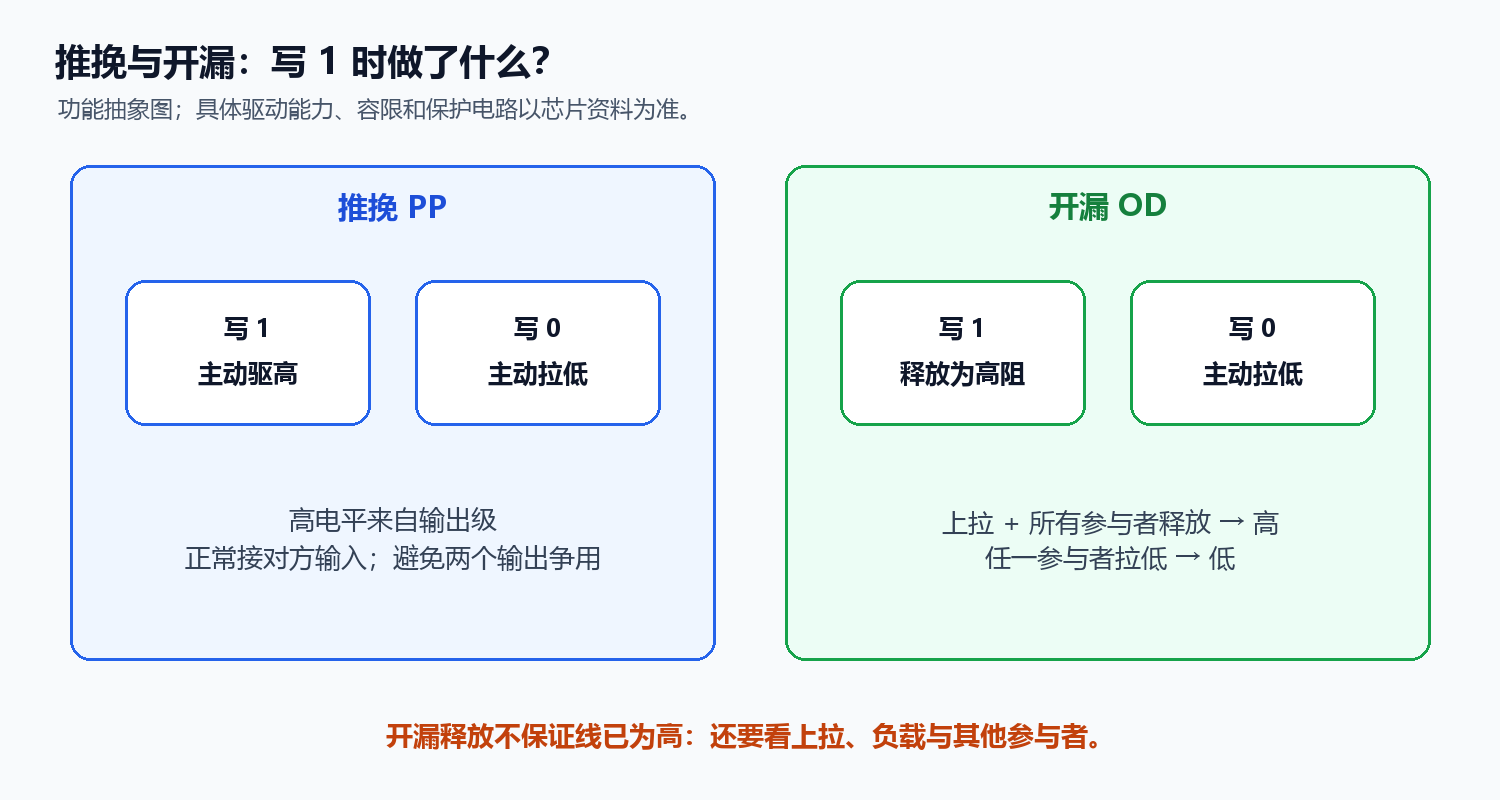

*自绘补充图：按功能抽象为驱动开关，未表示芯片的完整晶体管与保护电路。*

| 输出结构 | 写 0 | 写 1 | 高电平主要来自哪里 |
|---|---|---|---|
| 推挽 PP | 主动拉低 | 主动驱高 | 输出驱动级 |
| 开漏 OD | 主动拉低 | 释放为高阻 | 上拉或其他合适的外部电路 |

### 推挽输出

适合 LED 控制信号、普通数字控制或按外设要求配置的通信输出。可向外提供电流，也可从负载吸收电流，但均有额定限制。

两个推挽输出直接相连，一方驱高、一方驱低会形成争用，可能导致过流。**正常的推挽输出接到另一个器件输入**则是常见连接，并非“用了推挽就不能连接其他芯片”。

### 开漏输出

适合多个参与者共享、按协议拉低与释放的信号线。以外部上拉为例：

```text
所有参与者释放 → 上拉建立高电平
任一参与者拉低 → 线为低电平
```

这称作线与行为，I2C 是典型应用。成立前提包括兼容的电压域、上拉值、灌电流能力与正确的连接；开漏不是无限制防损坏模式。

上拉电阻过大可能让上升沿太慢，过小则增加低电平电流。内部弱上拉不自动满足总线速度要求，正式选值要结合负载电容、时序和数据手册。

如果本篇核心板 LED 仍采用 PB2 → LED → 电阻 → GND 的接线，直接改成开漏后写 1 只释放，不能期待像推挽一样供电点亮。


## 6. 输入、上下拉与逻辑阈值

| 输入方式 | 外部暂时不驱动时 | 典型接线 |
|---|---|---|
| 不启用内部上/下拉 | 电平由外部电路决定；真正悬空时不可靠 | 外部已有明确偏置或主动驱动 |
| 内部上拉 | 弱偏向高电平 | 按键按下接地，按下读低 |
| 内部下拉 | 弱偏向低电平 | 按键按下接适当电源，按下读高 |

“GPIO_PUPD_NONE”描述没有启用内部上下拉，**不一定意味着整个实际电路悬空**。课程 PA0 按键外部有下拉，所以可以使用这个参数。

数字输入应满足数据手册规定的 VIL/VIH 区间；中间区间不保证稳定判断。不能把“低于 1 V 为 0、高于 1 V 为 1”当作所有 GPIO 的统一门槛。

施密特输入采用滞回阈值，有助于缓慢或带噪声边沿的整形。它不自动消除所有机械按键抖动，也不等于完整的边沿脉冲发生器。

内部上拉/下拉通常较弱，不能替代负载供电。按键中外部电阻、电容和走线共同影响输入；软件要按实际电路解释“按下”。

### 模拟与复用模式

模拟模式把引脚配置为合适的模拟通路，并按芯片规则关闭相关数字通路。**设置模拟模式不会自动得到 ADC 数值**，还需配置对应 ADC 外设，且该引脚必须支持所选通道。

复用模式让 UART、SPI、定时器等外设控制引脚。GPIO 的 AF 编号来自具体引脚复用表，不可随意选一个 0～15 的数字。后续通信、定时器和 ADC 笔记再结合实例展开。


## 7. 时钟使能、初始化顺序与 SPL API

GD32F4xx GPIO 的典型初始化先使能对应端口时钟，再设置引脚配置。系统主频正确，不等于每个 GPIO 模块都已经启用。

```c
rcu_periph_clock_enable(RCU_GPIOB);
gpio_bit_reset(GPIOB, GPIO_PIN_2);  // 预装预期的关闭电平
gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
              GPIO_PUPD_NONE, GPIO_PIN_2);
gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                        GPIO_OSPEED_2MHZ, GPIO_PIN_2);
```

这是 PB2 高电平有效 LED 的初始化调用片段。提前设置输出锁存值，可减少切换为输出时的意外亮灯；实际复位瞬间的行为还受电路和芯片默认状态影响。

| API | 用途 |
|---|---|
| `rcu_periph_clock_enable` | 使能相应外设时钟 |
| `gpio_mode_set` | 模式与上下拉 |
| `gpio_output_options_set` | 输出类型与速度档位 |
| `gpio_bit_set` | 将所选输出位置为高 |
| `gpio_bit_reset` | 将所选输出位置为低 |
| `gpio_input_bit_get` | 读取一个指定引脚的输入逻辑状态 |
| `gpio_af_set` | 选择对应引脚复用功能，使用前查表 |

`GPIO_OSPEED_2MHZ` 是输出速度档位，不表示 LED 每秒亮灭二百万次。应用切换周期、驱动边沿能力与 CPU 时钟是三个不同的量。

本篇默认端口由当前示例管理。重复初始化同一引脚会覆盖之前的用途，接入新模块前先检查冲突；也不要无意关闭仍被其他模块使用的端口时钟。


## 8. 已核对的课程引脚表

| 资源 | 端口与引脚 | 本篇的逻辑解释 |
|---|---|---|
| 核心板 LED1 | PB2 | 高电平亮、低电平灭 |
| 核心板 KEY / WKUP | PA0 | 外部下拉；按下高、松开低 |
| 扩展板独立按键示例 | PC0 | 按下接地；启用上拉后按下低、松开高 |
| 扩展板八灯总开关 LED_SW | PC6 | 低电平使能 PNP 供电支路 |
| 扩展板 LED1～LED8 | PD8～PD15 | 总开关使能后，各位低电平点亮 |
| 蜂鸣器 BUZZER | PB9 | 高电平使 NPN 驱动级导通 |
| 矩阵 ROW1～ROW4 | PE8～PE11 | 用于行选择 |
| 矩阵 COL1～COL4 | PE12～PE15 | 用于列检测 |

核心板 LED1 与扩展板 LED1 同名，但引脚和有效电平不同。笔记中分别称“核心灯”和“八灯组”，避免混用。

表格基于课程正文与选定原理图，其他独立按键的完整引脚不能从 PC0 自动推断。芯片封装、核心板或扩展板版本不同，先以自己配套图纸核对。

引脚分配是应用接口的一部分。不要因为矩阵行和八灯都使用编号 8～15，就认为它们是同一组 GPIO；端口 E 和 D 是不同对象。


## 9. 核心灯：把有效电平藏在板级函数里

以下是函数定义片段，包含 `gd32f4xx.h` 与 `<stdbool.h>` 后使用：

```c
static void core_led_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOB);
    gpio_bit_reset(GPIOB, GPIO_PIN_2);
    gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_2);
    gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_2);
}

static void core_led_write(bool on)
{
    if (on) {
        gpio_bit_set(GPIOB, GPIO_PIN_2);
    } else {
        gpio_bit_reset(GPIOB, GPIO_PIN_2);
    }
}
```

调用者写 `core_led_write(true)` 表达“灯亮”，而不必在每个业务分支里记忆高低电平。换板以后集中修改板级映射，主流程仍清楚。

多个模块需要共享同一个灯时，应建立明确的控制规则。应用状态变量与 GPIO 真正输出可能被其他代码改变，不能默认一个函数保存的状态始终等于硬件状态。

单个位的置位/清零接口通常利用硬件提供的专用寄存器，避免整端口读改写覆盖别人的更新；但“翻转输出”往往涉及读取与再写，并非自动具有并发安全性。

本篇采用单一主循环管理 LED 状态。中断或任务也要写灯时，后续需要同步或把请求交给统一的控制模块。


## 10. 八灯电路：先开总开关，再选要亮的灯

课程扩展板使用 PNP 作为八灯的公共供电开关，PC6 控制其导通。LED 阳极共用供电，阴极支路经限流电阻连接 PD8～PD15。

| PC6 / LED_SW | 对应 PD 位 | 对应灯 |
|---:|---:|---|
| 1（关闭） | 任意 | 通常不亮 |
| 0（使能） | 1 | 灭 |
| 0（使能） | 0 | 亮 |

因此只把 PD8 拉低而忘了 PC6，不会得到预期亮灯；把全部 PD 位设高也不是“全部点亮”。

### 驱动电流路径

```text
供电 → PNP → LED → 限流电阻 → GPIO 低电平驱动级 → GND
```

GPIO 此时承担灌电流。PNP 帮助控制公共供电，并不代表每路 LED 电流绕过了 GPIO。

原理图可见各 LED 支路有 510 Ω 限流电阻，控制支路也有基极相关电阻。应结合真实供电、LED 正向压降、驱动压降和电流规格评估，不能把某个绝对最大电流数字当作长期工作目标。

例如**仅作计算示意**，假设支路电源 3.3 V、LED 压降 2.0 V、忽略其他压降：

```text
I ≈ (3.3 - 2.0) / 510 ≈ 2.55 mA
八路同时亮约为 8 × 2.55 ≈ 20.4 mA
```

这不是对课程板实际 VCC 的测量。还要分别核对单脚、端口、整芯片电流和高低电平条件，留出工作裕量。


## 11. 八灯驱动与流水灯片段

定义“bit0 对应扩展 LED1，bit7 对应扩展 LED8；位为 1 表示要亮”。下面在接口内部完成低电平映射。

```c
#define LED_BANK_MASK (GPIO_PIN_8  | GPIO_PIN_9  | GPIO_PIN_10 | \
                       GPIO_PIN_11 | GPIO_PIN_12 | GPIO_PIN_13 | \
                       GPIO_PIN_14 | GPIO_PIN_15)

static void led_bank_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOC);
    rcu_periph_clock_enable(RCU_GPIOD);

    gpio_bit_set(GPIOC, GPIO_PIN_6);  // 总开关先关闭
    gpio_mode_set(GPIOC, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_6);
    gpio_output_options_set(GPIOC, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_6);

    gpio_bit_set(GPIOD, LED_BANK_MASK);  // 各灯先关闭
    gpio_mode_set(GPIOD, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, LED_BANK_MASK);
    gpio_output_options_set(GPIOD, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, LED_BANK_MASK);
    gpio_bit_reset(GPIOC, GPIO_PIN_6);   // 使能公共供电
}

static void led_bank_write(uint8_t on_bits)
{
    uint32_t low_mask = ((uint32_t)on_bits << 8) & LED_BANK_MASK;
    gpio_bit_set(GPIOD, LED_BANK_MASK); // 先全灭，避免旧灯残留
    gpio_bit_reset(GPIOD, low_mask);
}
```

包含 `gd32f4xx.h` 与 `<stdint.h>` 后使用。这是面向该课程电路的板级函数，不作为任意 PNP 供电电路的通用接法。

流水灯调用片段，要求已经初始化与存在可靠的毫秒延时：

```c
for (unsigned int i = 0; i < 8U; ++i) {
    led_bank_write((uint8_t)(1U << i));
    delay_1ms(200U);
}
```

预期 LED1 到 LED8 依次点亮，每次只亮一灯。一轮名义时间 1.6 秒。`led_bank_write(0xFFU)` 全亮，`led_bank_write(0U)` 全灭。

函数只更新目标灯位，不向整个 GPIOD 写一个固定值覆盖其他用途。两个写操作之间仍存在短暂全灭状态；若要求严密同步输出，需要按硬件能力另行设计。


## 12. 三极管与 MOS 管：用于理解控制，不套绝对结论

课程通过三极管、MOS 管解释 GPIO 驱动级与板载开关。对软件学习最有用的是找出控制极性和电流路径。

| 器件 | 控制中要关注什么 | 常见用途 |
|---|---|---|
| NPN / PNP | 基极电流、基极与发射极关系、限流和饱和条件 | 板级开关与驱动 |
| NMOS / PMOS | 栅源电压 VGS、所需导通能力、栅电荷与体二极管 | 低侧/高侧开关与驱动 |

“N 型高电平导通、P 型低电平导通”只适用于已明确参考节点的常见接法。真正决定 MOS 导通的是栅极相对源极的电压，不能只看栅极相对地。

MOS 栅极理想直流电流很小，切换时仍需充放电栅电容，不是“没有电流”。MOS 也大量用于大功率场景；速度、功耗与负载能力取决于具体器件和驱动条件，不能把 MOS 限定为低功率、三极管限定为高功率。

GPIO 不直接供电驱动电机、继电器或任意蜂鸣器。使用匹配的驱动级，检查共地、电平、电流及感性负载保护。芯片保护二极管也不是允许任意过压、争用或反向供电的设计手段。

本篇按已经核对的课程板进行软件控制；独立设计驱动电路时再结合前面的数电模电笔记和器件规格。


## 13. 两种独立按键接线，按下电平不同

### 核心板 PA0：外部下拉，按下读高

```c
rcu_periph_clock_enable(RCU_GPIOA);
gpio_mode_set(GPIOA, GPIO_MODE_INPUT,
              GPIO_PUPD_NONE, GPIO_PIN_0);
bool pressed = (gpio_input_bit_get(GPIOA, GPIO_PIN_0) == SET);
```

外部电阻提供默认低电平，按下后与 3V3 接通。这里无需内部上下拉；引脚在系统中的 WKUP 名称不改变本例的 GPIO 电平读取方式。

### 扩展 PC0 示例：内部上拉，按下读低

```c
rcu_periph_clock_enable(RCU_GPIOC);
gpio_mode_set(GPIOC, GPIO_MODE_INPUT,
              GPIO_PUPD_PULLUP, GPIO_PIN_0);
bool pressed = (gpio_input_bit_get(GPIOC, GPIO_PIN_0) == RESET);
```

未按下时由上拉提供高电平，按下时接地变为低电平。先把 raw 电平归一化成 pressed，后续消抖和业务逻辑就不用反复关心极性。

同名局部变量属于两个独立示意片段，不把两段并排粘贴到一个作用域重复声明。输入初始化一般不需要配置推挽输出类型；输入上拉是弱偏置，不是主动高电平输出。

读取一个指定引脚时检查 API 返回规则；本库使用 SET/RESET 逻辑状态。读取整个输入端口的掩码类接口与这个单脚接口的结果形式可能不同。


## 14. 按住点灯与按一次翻转是不同需求

| 需求 | 需要的信息 | 处理方式 |
|---|---|---|
| 按住亮、松开灭 | 稳定按键状态 | LED 跟随状态 |
| 每按一次翻转亮灭 | 稳定的按下事件 | 按下事件时更新 LED 状态 |
| 长按触发功能 | 状态、开始时间与持续时长 | 计时并明确只触发一次还是重复 |
| 按住连发 | 首次事件、延时和连发间隔 | 显式制定连发规则 |

按住点灯的调用片段：

```c
bool pressed = (gpio_input_bit_get(GPIOA, GPIO_PIN_0) == SET);
core_led_write(pressed);
```

它直接使用原始状态，适合先验证接线，不是完善的消抖方案。

下面是**错误思路示意**：

```c
if (pressed) {
    led_on = !led_on;  // 主循环每轮翻转，长按会重复触发
}
```

即使原始电平没有抖动，循环多次也会翻转多次。因此一次触发需要两个条件：先得到可靠的稳定状态，再识别从“未按下”到“按下”的状态转变。

“延时后再读一次”能缓解部分抖动，但不能自动定义长按、释放、连发和多键规则。先写清需求，才知道何时产生事件。


## 15. 机械抖动与消抖方法

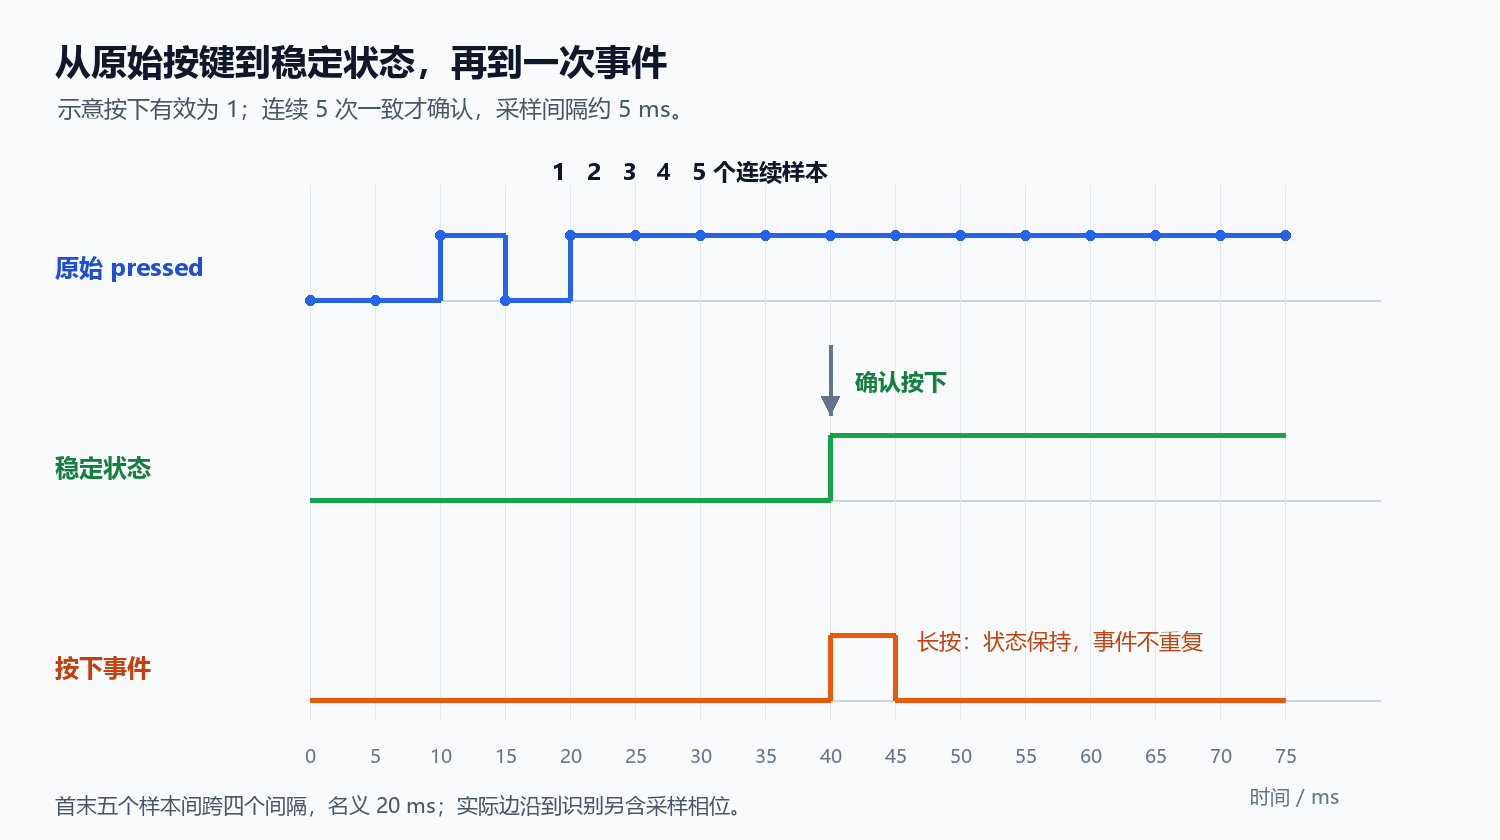

*自绘补充图：以按下为高的按键说明，时间仅为教学示意；低电平有效按键先归一化。*

机械触点接通/断开时可能短暂反复变化。课程给出延时复查、节拍计时等方案；实际抖动长度受按键、接线和环境影响，不把固定 5～10 ms 当作保证。

| 方法 | 优点 | 主要边界 |
|---|---|---|
| RC 与合适输入电路 | 降低部分高频变化 | 时常数、电压阈值和边沿需评估 |
| 延时后复读 | 直观、适合初学 | 阻塞主循环，两次读数不能证明中间始终稳定 |
| 周期采样连续确认 | 状态明确、适合多按键 | 采样必须足够规律，需设阈值 |
| 基于时间戳的状态机 | 便于调度、长按和连发 | 时间源和回绕规则需设计 |

本篇补充“每约 5 ms 采样、连续 5 次相同才接受”的算法。第一到第五次采样之间跨 4 个间隔，名义为 **20 ms**；从物理边沿到识别还包括等候下一次采样的相位。

它只保证所观察的样本一致，不能证明两次采样之间电平从未变化。采样间隔变长、主循环阻塞或噪声规律变化，都需要重新评估。

按下和松开都要消抖。松开不可靠可能让下一次按下被丢失，或让一次按住被分成多个事件。


## 16. 单按键消抖：稳定状态与事件分开输出

包含 `<stdbool.h>`、`<stdint.h>` 后使用。以下函数定义片段按每次调用输入一个“已归一化”的 raw_pressed。

```c
#define KEY_CONFIRM_SAMPLES 5U

typedef struct {
    bool candidate;
    bool stable;
    uint8_t count;
} KeyFilter;

static bool key_filter_step(KeyFilter *filter, bool raw_pressed)
{
    if (raw_pressed != filter->candidate) {
        filter->candidate = raw_pressed;
        filter->count = 1U;
    } else if (filter->count < KEY_CONFIRM_SAMPLES) {
        ++filter->count;
    }

    if (filter->count == KEY_CONFIRM_SAMPLES &&
        filter->stable != filter->candidate) {
        filter->stable = filter->candidate;
        return filter->stable;  // 只在稳定按下的转变时返回 true
    }
    return false;
}
```

调用者须保证 filter 指向独立、有效且已初始化的对象。`KeyFilter filter = {0};` 表示初始稳定状态为“未按下”。计数饱和后不再递增，避免长按导致回绕。

| 输入过程 | filter.stable | 函数返回 |
|---|---|---|
| 未确认的抖动 | 保持原状态 | false |
| 连续 5 次按下样本 | 更新为 true | 在更新那次为 true |
| 长期按住 | true | false |
| 连续 5 次释放样本 | 更新为 false | false |
| 再次稳定按下 | 更新为 true | 再产生一次 true |

本函数的 false 不表示“目前未按下”，只表示“本次没有新的按下事件”。目前是否按下要读取 stable。

若上电时按键已按住，该初始策略会在确认后产生一次按下事件；若业务要求必须先释放再接收首次按下，应增加启动锁定规则。


## 17. 完整 main.c：核心按键每按一次翻转核心灯

这是基于第 03 篇匹配模板的完整应用源文件。要求基础 1 ms 的 SysTick、delay_1ms 和唯一的 SysTick_Handler 正常工作；模板启动时钟配置正确。使用课程 PA0 按下高、PB2 灯亮高的映射。

```c
#include "gd32f4xx.h"
#include "systick.h"
#include <stdbool.h>
#include <stdint.h>

#define KEY_CONFIRM_SAMPLES 5U

typedef struct {
    bool candidate;
    bool stable;
    uint8_t count;
} KeyFilter;

static bool key_filter_step(KeyFilter *filter, bool raw_pressed)
{
    if (raw_pressed != filter->candidate) {
        filter->candidate = raw_pressed;
        filter->count = 1U;
    } else if (filter->count < KEY_CONFIRM_SAMPLES) {
        ++filter->count;
    }
    if (filter->count == KEY_CONFIRM_SAMPLES &&
        filter->stable != filter->candidate) {
        filter->stable = filter->candidate;
        return filter->stable;
    }
    return false;
}

static void board_gpio_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOA);
    rcu_periph_clock_enable(RCU_GPIOB);
    gpio_mode_set(GPIOA, GPIO_MODE_INPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_0);
    gpio_bit_reset(GPIOB, GPIO_PIN_2);
    gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_2);
    gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_2);
}

static void core_led_write(bool on)
{
    if (on) {
        gpio_bit_set(GPIOB, GPIO_PIN_2);
    } else {
        gpio_bit_reset(GPIOB, GPIO_PIN_2);
    }
}

int main(void)
{
    KeyFilter key = {0};
    bool led_on = false;
    systick_config();
    board_gpio_init();

    while (1) {
        bool raw_pressed =
            (gpio_input_bit_get(GPIOA, GPIO_PIN_0) == SET);
        if (key_filter_step(&key, raw_pressed)) {
            led_on = !led_on;
        }
        core_led_write(led_on);
        delay_1ms(5U);
    }
}
```

预期：稳定按下第一次灯亮，长按不继续翻转；稳定释放后再次按下灯灭。代码执行与中断开销会使实际采样间隔略偏离 5 ms，不能用它承担严格实时任务。

想改成按住亮、松开灭，可用下面的循环替换整个原 while 循环，此时不再需要 led_on 变量：

```c
while (1) {
    bool raw_pressed =
        (gpio_input_bit_get(GPIOA, GPIO_PIN_0) == SET);
    (void)key_filter_step(&key, raw_pressed);
    core_led_write(key.stable);
    delay_1ms(5U);
}
```

这里继续采样并更新滤波状态，只是不使用按下事件返回值。每轮按稳定状态设置灯，不再执行另一次 led_on 写灯操作。

本程序单独作为一个实验，不能与第 03 篇的另一个 main.c 同时加入工程。测试后再把滤波函数移入独立模块复用。


## 18. 多个独立按键与轮询响应时间

每个按键需要独立的滤波状态，不能让几个按键共用一个 candidate/count。

```c
KeyFilter keys[4] = {0};
```

这是状态数组声明片段。实际四个输入的端口、电平与读取接口，先从扩展板原理图逐项登记，不从 PC0 推断其余映射。

一轮对所有按键读取并更新，再统一等待或按节拍安排下一轮。不要给每个键分别阻塞 20 ms，使四键扫描额外累积成很长的等待。

| 影响 | 例子 |
|---|---|
| 采样周期 | 越长越容易漏掉短促按压 |
| 消抖门槛 | 越长通常越稳，但响应更慢 |
| 其他阻塞任务 | 播放整首曲子时不扫描，松开无法及时识别 |
| 事件队列/标志 | 业务处理速度不足时要明确丢弃或保存策略 |

延时轮询适合这一篇的基础实验；任务增加后，需要节拍、定时器或调度机制。输入中断也不自动消除抖动，仍需要状态处理。

本篇的多键政策是每个独立按键可分别处理；后面的无二极管矩阵则按单键设计，两者不要混淆。


## 19. 蜂鸣器：有源与无源的控制不同

| 类型 | 常见驱动方式 | 持续直流通常表现 |
|---|---|---|
| 有源蜂鸣器 | 按规格提供供电或使能 | 内部振荡器发出其固有声音 |
| 无源蜂鸣器/声学换能器 | 外部提供周期波形 | 不产生持续的目标音高，可能只有瞬态声 |

“源”在这里指振荡源，不是有没有电源引脚。不要把所有蜂鸣器都描述成内部有固定振荡器，又同时要求外部给出音频频率。

课程用 PB9 的周期切换产生不同音高，本篇按**需要外部音频波形**的应用方式理解；具体器件类型、额定电压与频响以板上器件规格为准。

### 课程驱动级

已查看的原理图中，PB9 经基极电阻控制 NPN；负载由 VCC 供电，NPN 接到 GND 一侧，带有相应保护二极管与下拉电阻。高电平使驱动导通，低电平截止。

```c
static void buzzer_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOB);
    gpio_bit_reset(GPIOB, GPIO_PIN_9);  // 初始静音/截止
    gpio_mode_set(GPIOB, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, GPIO_PIN_9);
    gpio_output_options_set(GPIOB, GPIO_OTYPE_PP,
                            GPIO_OSPEED_2MHZ, GPIO_PIN_9);
}
```

这是函数定义片段，不代表 GPIO 能直接承担任意蜂鸣器的负载电流。声音响度由器件、驱动电压、波形和频率等决定，频率变高不等于一定更响。


## 20. 声音频率：一次完整高低周期才算一次

频率 f 表示每秒的完整周期数。占空比 50% 的方波，高、低各持续半个周期。

```text
T = 1 / f
T_us = 1000000 / f
half_us ≈ 500000 / f
```

| 目标频率 | 名义完整周期 | 名义半周期 |
|---:|---:|---:|
| 1000 Hz | 1000 µs | 500 µs |
| 500 Hz | 2000 µs | 1000 µs |
| 440 Hz | 约 2272.7 µs | 约 1136.4 µs |

连续翻转 1000 次电平只形成约 500 个完整周期。若每秒“置高再置低”执行 1000 轮，才是 1000 Hz 的完整周期请求。

整数微秒计数会带来量化误差。例如取 half_us = 1136，理想方波频率为 `1000000 / (2 × 1136) ≈ 440.14 Hz`；调用、GPIO 写入和中断开销还会改变实际波形。

**音高与时值分开表示：**频率定义音高，持续多久定义音符时值；休止符应停止驱动，而不是把 0 当作除数计算周期。

教材中的歌曲演示帮助练习循环与数组。乐谱节拍、音符频率和蜂鸣器实际响应仍是不同层次，学习时先验证一两个单音，再增加整曲。


## 21. 软件方波片段与微秒延时的前提

以下函数定义片段需要 `gd32f4xx.h`、`systick.h`、`<stdbool.h>`、`<stdint.h>`；要求已经初始化 PB9，并有**已验证单位与行为**的 delay_1us 实现。

```c
static bool tone_burst(uint32_t frequency_hz, uint32_t cycles)
{
    if (frequency_hz == 0U || cycles == 0U) {
        gpio_bit_reset(GPIOB, GPIO_PIN_9);
        return true;  // 静音请求
    }
    if (frequency_hz < 100U || frequency_hz > 5000U ||
        cycles > 10000U) {
        gpio_bit_reset(GPIOB, GPIO_PIN_9);
        return false; // 本例的演示范围
    }
    uint32_t half_us = 500000U / frequency_hz;
    for (uint32_t i = 0; i < cycles; ++i) {
        gpio_bit_set(GPIOB, GPIO_PIN_9);
        delay_1us(half_us);
        gpio_bit_reset(GPIOB, GPIO_PIN_9);
        delay_1us(half_us);
    }
    return true;
}
```

`tone_burst(1000U, 200U)` 请求约 200 ms 的 1 kHz 方波，属于按理论周期推导的结果。实际执行时间加上软件开销，不能保证恰好 200 ms；也不一定在任意器件上产生相同响度。

这是**阻塞式演示**：生成声音期间主循环不能持续扫描所有输入。cycles 设得越大，输入响应间隔越长；不要用整首曲子的阻塞播放实现实时键盘跟随。

课程蜂鸣器页提供了 systick.c 替换示例，但本次未验证其完整长代码。只添加 delay_1us 声明不会产生实现，也不要未经核对就覆盖原有 SysTick Handler 或改变全工程节拍。

第 03 篇提过可选的每微秒中断方案，它可能引入每秒一百万次事件，并非本例唯一可用的微秒延时方式。微秒测时可以由适当硬件计数实现；定时器 PWM 更适合持续稳定音频，第 05 篇再整理。


## 22. 矩阵键盘：行列坐标换取较少引脚

N 行、M 列可安排 N × M 个按键，通常需要 N + M 根行列线。4×4 提供 16 键、使用 8 个信号引脚；3×4 提供 12 键、使用 7 个引脚。

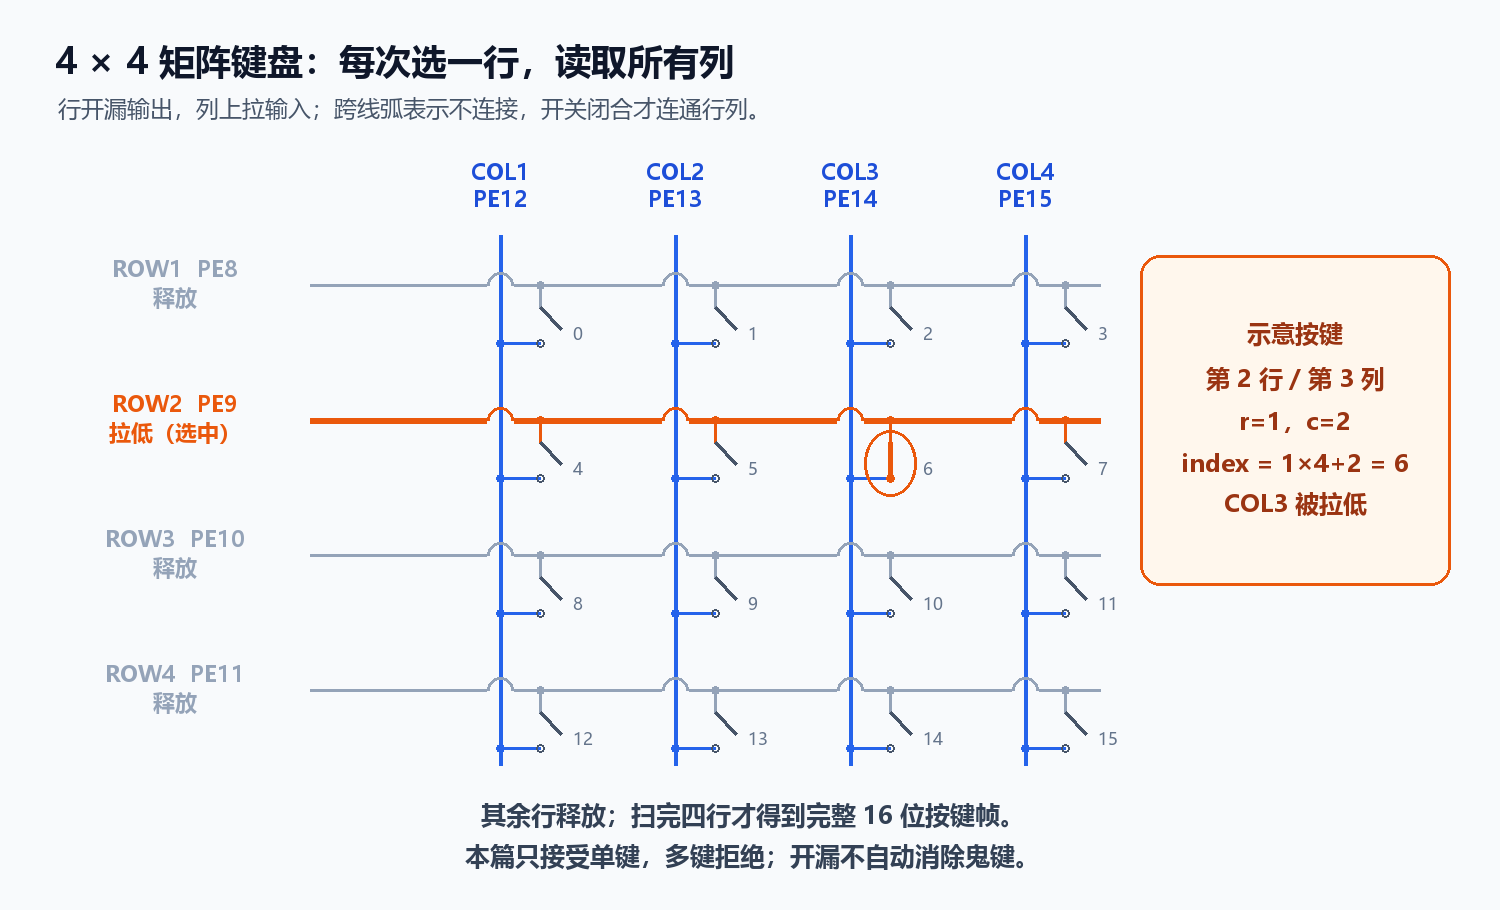

*自绘补充图：按钮闭合才连通行列；示意按下第 2 行、第 3 列，编号规则见后文。*

行线与列线在图上交叉，并不表示天然导通。按下某键才把对应行与列连接起来，软件需要从电平中恢复坐标。

课程采用先让所有行输出低、检测列，再交换行列方向检测行的方法，适合理解单键定位。多个按键同时按下时，仅靠行列集合未必能唯一配对。

本篇补充**逐行扫描**：列上拉输入，行开漏输出；每次只把选中行拉低，其他行释放。读取哪些列被拉低，再换下一行。

这个方案不需要不断交换输入输出方向，也避免把未选行主动推高与选中低电平行形成争用；仍然需要建立稳定时间、消抖及多键策略。


## 23. 矩阵扫描规则与编号

本篇使用课程引脚：ROW1～ROW4 为 PE8～PE11，COL1～COL4 为 PE12～PE15。内部 r、c 从 0 开始，应用键号定义为：

```text
key_index = r × 4 + c，范围 0～15
第 2 行、第 3 列 → r=1，c=2 → index=6
```

这个软件编号不自动等于板上 S1～S16 丝印方向；需要按实际排布建立映射。

### 一帧逐行扫描

1. 释放全部行。
2. 拉低当前行。
3. 等待线路按负载与上拉条件建立有效电平。
4. 读取四列，低电平表示该行对应键可能闭合。
5. 释放当前行，继续下一行。
6. 保存整个帧的 16 位结果，再消抖和解释。

读到一列低不代表整个帧只有一个键。不能一找到第一键就跳过其他行，否则无法判断多键或鬼键。

行使用开漏时，写高表示释放；列的弱上拉通过按键提供行低电平时的电流路径。开漏方案仍要求电压、电流和上拉参数正确。

本篇采用单键政策：0 位有效表示无键，恰好 1 位有效返回对应键，多位有效拒绝作为单键结果。它不是多键无冲突键盘。


## 24. 矩阵驱动：返回整个按键位图

下面的函数定义片段需要 GPIOE 和匹配 SDK；delay_1us 要满足第 21 节前提。20 µs 是学习用的建立时间起点，实际按线电容、上拉和测量调整。

```c
#define MATRIX_ROW_MASK (GPIO_PIN_8 | GPIO_PIN_9 | \
                         GPIO_PIN_10 | GPIO_PIN_11)
#define MATRIX_COL_MASK (GPIO_PIN_12 | GPIO_PIN_13 | \
                         GPIO_PIN_14 | GPIO_PIN_15)

static const uint32_t row_pins[4] = {
    GPIO_PIN_8, GPIO_PIN_9, GPIO_PIN_10, GPIO_PIN_11
};
static const uint32_t col_pins[4] = {
    GPIO_PIN_12, GPIO_PIN_13, GPIO_PIN_14, GPIO_PIN_15
};

static void matrix_init(void)
{
    rcu_periph_clock_enable(RCU_GPIOE);
    gpio_bit_set(GPIOE, MATRIX_ROW_MASK);
    gpio_output_options_set(GPIOE, GPIO_OTYPE_OD,
                            GPIO_OSPEED_2MHZ, MATRIX_ROW_MASK);
    gpio_mode_set(GPIOE, GPIO_MODE_OUTPUT,
                  GPIO_PUPD_NONE, MATRIX_ROW_MASK);
    gpio_mode_set(GPIOE, GPIO_MODE_INPUT,
                  GPIO_PUPD_PULLUP, MATRIX_COL_MASK);
}

static uint16_t matrix_scan_frame(void)
{
    uint16_t bitmap = 0;
    gpio_bit_set(GPIOE, MATRIX_ROW_MASK); // 释放全部行
    for (unsigned int r = 0; r < 4U; ++r) {
        gpio_bit_reset(GPIOE, row_pins[r]);
        delay_1us(20U);
        for (unsigned int c = 0; c < 4U; ++c) {
            if (gpio_input_bit_get(GPIOE, col_pins[c]) == RESET) {
                bitmap |= (uint16_t)(1UL << (r * 4U + c));
            }
        }
        gpio_bit_set(GPIOE, row_pins[r]);
    }
    return bitmap;
}
```

初始化顺序先准备释放值和开漏类型，再切换输出，减少初始推挽状态带来的争用机会。扫描期间当前行由本驱动独占管理，别的任务不能同时改它的模式。

位图中 bit0 对应 r0/c0，bit15 对应 r3/c3。使用 `1UL` 让移位操作数足够宽，位移量明确限制为 0～15；最后保存到 uint16_t。

四次等待名义合计至少 80 µs，完整帧还包括 GPIO 读写和循环开销。建立时间足够不代表已经消抖，二者是不同时间尺度的问题。


## 25. 单键筛选、鬼键与矩阵消抖

把位图转换成一个单键号或状态码：

```c
#define MATRIX_NONE  (-1)
#define MATRIX_MULTI (-2)

static int matrix_single_key(uint16_t bitmap)
{
    if (bitmap == 0U) {
        return MATRIX_NONE;
    }
    uint32_t bits = bitmap;
    if ((bits & (bits - 1U)) != 0U) {
        return MATRIX_MULTI;
    }
    for (unsigned int i = 0; i < 16U; ++i) {
        if ((bits & (1UL << i)) != 0U) {
            return (int)i;
        }
    }
    return MATRIX_MULTI;
}
```

`bits & (bits - 1)` 在非零时为 0，表示只有一位为 1。先处理 0，避免把无键解释成合法键。

### 鬼键

没有逐键隔离二极管的矩阵中，三个矩形角的键闭合可能通过线路形成第四个角的假信号。开漏解决输出争用问题，**不会自动解决鬼键**。

本例只接收单键，并在多位结果时拒绝输出音符；需要可靠多键/和弦时，应采用合适的硬件隔离和对应扫描方案，不能只扩大一个数组。

### 对键号消抖

对 `MATRIX_NONE` 与 0～15 的键号，维护候选键、连续确认次数和稳定键。若出现 MATRIX_MULTI，本篇策略立即静音、关闭灯光并清除确认状态，再等待合法单键重新稳定。

不要把 MULTI 转换成 unsigned 后当作数组下标；读取音符表前必须保证 `0 <= key && key < 16`。无键和多键是不同原因，调试记录也应分开。


## 26. 声光电子琴：模块接口与映射表

课程整合矩阵键盘、八灯和蜂鸣器。把它拆成接口，会更容易定位问题：

| 模块 | 输入/输出 | 负责什么 |
|---|---|---|
| 矩阵驱动 | 16 位原始位图 | GPIO 扫描与线路建立 |
| 单键筛选 | NONE / MULTI / 0～15 | 明确本篇单键政策 |
| 消抖器 | 稳定键号 | 拒绝瞬态变化 |
| 音符映射 | 键号 → 频率 | 乐音数据，而不是端口访问 |
| 八灯驱动 | 应用亮灯位图 | PC6/PD8～PD15 的有效电平映射 |
| 发声模块 | 频率、周期数 | 方波输出，后续可换定时器 |

学习用频率表，近似覆盖两个八度中的 16 个音：

```c
static const uint16_t note_hz[16] = {
    262, 294, 330, 349, 392, 440, 494, 523,
    523, 587, 659, 698, 784, 880, 988, 1047
};
```

这是示例映射，不是对课程乐谱原样抄录。第 7/8 键号的 523 Hz 重复，是这份分组映射的约定；需要连续半音阶时换成相应频率表。

让 key%8 对应八灯中一灯，前八键与后八键复用灯位；若要显示八度或其他状态，可以另加业务规则。

音符表使用频率值，GPIO 代码不必知道歌曲名称。未来改成定时器 PWM，输入和业务接口仍可保留。


## 27. 轮询电子琴整合片段与响应边界

下面是**整合片段**，与第 11、21、24、25、26 节的函数/定义放在同一个独立实验中，并使用满足前提的延时与模板。它不是另附的完整 SDK 工程。

定义矩阵键号滤波器：

```c
typedef struct {
    int candidate;
    int stable;
    uint8_t count;
} MatrixFilter;

static void matrix_filter_step(MatrixFilter *filter, int raw_key)
{
    if (raw_key == MATRIX_MULTI) {
        filter->candidate = MATRIX_NONE;
        filter->stable = MATRIX_NONE;
        filter->count = 0U;
        return;
    }
    if (raw_key != filter->candidate) {
        filter->candidate = raw_key;
        filter->count = 1U;
    } else if (filter->count < 5U) {
        ++filter->count;
    }
    if (filter->count == 5U) {
        filter->stable = filter->candidate;
    }
}
```

主循环整合示意：

```c
int main(void)
{
    MatrixFilter filter = {MATRIX_NONE, MATRIX_NONE, 0};
    systick_config();
    led_bank_init();
    buzzer_init();
    matrix_init();

    while (1) {
        int raw_key = matrix_single_key(matrix_scan_frame());
        matrix_filter_step(&filter, raw_key);
        int key = filter.stable;
        if (key >= 0 && key < 16) {
            led_bank_write((uint8_t)(1U << ((unsigned int)key % 8U)));
            (void)tone_burst(note_hz[key], 2U);
        } else {
            led_bank_write(0U);
            gpio_bit_reset(GPIOB, GPIO_PIN_9);
            delay_1ms(5U);
        }
    }
}
```

本例每次只生成两个周期，再回来扫描，避免一次阻塞播放整曲。**它的采样间隔不是固定 5 ms：**无键时约 5 ms，有声时受当前音符两个周期、扫描时间与软件开销影响。因此这里的“5 个样本确认”不能统一叫作 20 ms 消抖。

最低示例频率 262 Hz 的两个名义周期约为 7.63 ms；1047 Hz 的两个周期约为 1.91 ms。释放确认、换键响应和声音间隙都会随音高变化，不能保证音准、连续音色或固定响应时间。

预期行为：单键稳定后点亮对应灯并重复产生该音；确认松开后静音灭灯；出现多键结果时立即静音并清除稳定键。片段用于理解模块组合，正式电子琴应将定时扫描与硬件持续发声分离。

第 05 篇学习定时器后，可让固定节拍负责按键扫描，PWM 负责连续声音，让主循环只处理事件。


## 28. 总线与时钟：使能和频率各做一件事

GPIO 属于芯片片上外设。CPU 通过总线访问配置和状态，外设还需相应时钟；真实拓扑查看 GD32F4xx 框图。

| 名称 | 本篇需要理解的含义 |
|---|---|
| AHB | 常用于较高性能的片上互连与资源访问 |
| APB | 常用于较简单的外设寄存器访问 |
| 时钟树 | 时钟源、PLL、分频与各模块的时钟分配 |
| RCU 使能 | 打开相应外设时钟门控 |
| 内核频率 | CPU 执行节拍，与 GPIO 输出速度档位不同 |

总线不是每到一次晶振周期便“轮流扫描所有房子”的软件任务调度器。CPU/DMA 等产生访问请求，互连按实际协议完成传输；时钟为同步逻辑提供节拍。

课程以外部 8 MHz 晶振和预期 168 MHz 配置说明倍频，`168/8=21` 是总体频率比。真实 PLL 通常有输入分频、倍频与输出分频，还受各级频率范围限制，不能把 21 随便写进任一寄存器就完成配置。

内部时钟源的频率与可用模块属于具体器件特性，不把课程一张图的所有数值当作 ARM 内核统一规定。GPIO 不工作时先看端口使能；多个外设时序一起异常时再核对全局时钟与软件声明。


## 29. 常见错误与排查顺序

| 现象 | 优先检查 |
|---|---|
| PB2 能亮，扩展灯不亮 | PC6 总开关、PD8～PD15 映射与低电平有效 |
| 所有灯反着亮 | 软件 on 位与硬件低电平映射是否一致 |
| 写 1 但开漏引脚不高 | 是否有合适上拉、其他参与者是否仍拉低 |
| 按键无操作也随机变化 | 外部偏置、内部上下拉、是否真实悬空 |
| 按下与松开逻辑相反 | 输入电平有没有归一化成 pressed |
| 一次按键触发多次 | 消抖、状态边沿、是否每轮按住都触发 |
| 第一次有效，之后不响应 | 释放消抖是否建立，稳定状态有没有更新 |
| 微秒函数链接失败 | 只有声明、没有实现，或对应源码未构建 |
| 蜂鸣器只响一下 | 器件/驱动方式、是否输出了完整周期波形 |
| 声音频率相差约两倍 | 是否把翻转次数误当成完整周期数 |
| 播放声音时按键迟钝 | 阻塞时长与扫描周期，是否连续播放整曲 |
| 矩阵只知道列 | 有没有逐行定位或完成课程的反向检测 |
| 多键产生假位置 | 鬼键、扫描争用、多键政策与硬件隔离 |
| 某键触发错误音或越界 | r/c 编号、NONE/MULTI 检查和数组范围 |
| 新增外设后老功能失效 | 端口模式覆盖、复用、引脚资源冲突 |

排查顺序：

```text
电路与引脚 → 外设时钟 → 模式与电平 → 原始输入/输出
→ 采样与时序 → 稳定状态 → 应用事件与映射
```

先只验证一个引脚、一键、一灯，再增加数组和组合控制。断点可以看逻辑路径，但会改变扫描和发声时序；测量频率时连续运行，并用合适仪器观察真实波形。

改变驱动电路之前查规格，不把保护二极管或最大电流作为兜底。课程原理图与本篇计算示意分别说明，实际供电电压不要凭名字 VCC 猜。


## 30. 实验验收与动手练习

| 实验 | 验收标准 |
|---|---|
| 核心灯 | 能解释 PB2 的高低与亮灭对应 |
| 八灯 | 总开关正确，单灯/全亮/全灭与位图一致 |
| 按住点灯 | 稳定按下亮、稳定松开灭 |
| 每按一次翻转 | 长按不重复，释放后再按能再次触发 |
| 单音 | 解释周期、半周期，测量实际输出而非只凭听感 |
| 矩阵单键 | 16 个位置映射正确，无键与多键有明确处理 |
| 模块整合 | 按键、灯位与音符一致，知道阻塞和音频间隙限制 |

### 自测

1. PB2 是封装第 2 脚吗？GPIO_PIN_2 是传入下标 2 吗？
2. 开漏写 1 后，为什么线可能仍是低电平？
3. 使用 GPIO_PUPD_NONE 是否一定代表整个电路悬空？
4. 为什么课程 PA0 按下是高，而 PC0 示例按下是低？
5. PC6 与 PD8～PD15 各负责什么？为什么八灯组“位为 1 表示亮”需要软件映射？
6. 滤波函数返回 false，是否意味着按键当前松开？
7. 每 5 ms 取样，连续 5 个样本相同，首末样本相隔多久？
8. 方波每秒翻转 2000 次电平，完整周期频率是多少？
9. 4×4 键盘需要多少行列线？第 2 行、第 3 列在本篇的键号是多少？
10. 开漏扫描是否自动支持无鬼键多键识别？
11. MATRIX_MULTI 可以直接拿来访问 note_hz 吗？
12. 整合片段中 5 个确认样本为什么不能统一称为 20 ms？

### 动手练习

1. 用 0x01、0x80、0x55、0xAA 控制八灯，先写出亮灯编号，再实验核对。
2. 把第 17 节改成“按住亮、松开灭”，复用滤波状态并解释事件与状态的区别。
3. 记录一段归一化按键样本：`0,1,0,1,1,1,1,1,1,0,1,0,0,0,0,0`。逐次推导 candidate/count/stable 和按下事件。
4. 按顺序验证矩阵的 16 个位置，登记实际丝印和 r/c/index 的映射；观察多键时的拒绝策略。
5. 生成 500 Hz 与 1000 Hz 的短方波，测量周期，再比较软件开销。
6. 设计“按键改变流水灯速度”的接口：输入事件只修改速度状态，灯光模块按状态运行，避免在按键处理中阻塞整轮流水灯。

本次未执行这些硬件实验，验收标准由学习者实际编译、下载与测量确认。


## 31. 参考答案与关键算例

| 题号 | 参考答案 |
|---|---|
| 1 | 不是；端口内位号、封装脚号、选择掩码是不同概念 |
| 2 | 写 1 只释放，需要上拉；另一个器件或负载仍可能拉低 |
| 3 | 不一定，外部下拉/上拉或主动驱动可能已确定电平 |
| 4 | 两个按键电路不同，一个按下接 3V3，一个按下接 GND |
| 5 | PC6 控制公共供电，PD 位控制阴极；硬件低亮需把应用亮灯位转成拉低掩码 |
| 6 | 不是；false 表示本次没有新按下事件，目前状态查看 stable |
| 7 | 4 个间隔，名义 20 ms；边沿到识别还包含采样相位 |
| 8 | 1000 Hz，两个翻转组成一个完整高低周期 |
| 9 | 8 根；r=1、c=2，对应 index=6 |
| 10 | 不支持；开漏避免特定争用，鬼键还需硬件/算法策略 |
| 11 | 不可以，它是 -2，需先验证键号 0～15 |
| 12 | 发声与扫描阻塞随频率变化，样本不是固定周期取得 |

八灯位图练习：

| on_bits | 对应亮灯 | 应拉低的 GPIOD 目标位掩码 |
|---|---|---|
| 0x01 | LED1 | 0x0100 |
| 0x80 | LED8 | 0x8000 |
| 0x55 | LED1、3、5、7 | 0x5500 |
| 0xAA | LED2、4、6、8 | 0xAA00 |

给定滤波序列按第 16 节从 `{0}` 初始化：第 8 个样本首次确认按下，产生一次事件；第 16 个样本确认释放。第 9 个样本为继续按住，不再产生事件。

其他关键算例：一轮八灯 × 200 ms = 1.6 秒；1 kHz 的半周期为 500 µs；2 个 262 Hz 周期约为 7.63 ms；r3/c3 的 index=15，对应 bitmap=0x8000。


## 32. 一页复习与十二篇路线

| 主题 | 记住这条规则 |
|---|---|
| GPIO 模式 | 功能、输出结构、上下拉与复用分别配置 |
| 电平 | 数据手册定义逻辑范围，原理图定义有效极性 |
| 推挽 | 主动驱高/拉低，不能让两个相反输出争用 |
| 开漏 | 写 1 释放，写 0 拉低，高电平需要适当来源 |
| LED | 控制位与亮灯状态由接线决定 |
| 输入 | 先归一化 pressed，再做滤波和事件处理 |
| 按键 | 稳定状态与一次事件是两个输出 |
| 蜂鸣器 | 完整周期决定频率，微秒延时需要真实实现和验证 |
| 矩阵 | 完整帧定位，明确单键/多键/鬼键政策 |
| 整合 | 阻塞时长影响采样，硬件定时能分离任务 |
| 电流 | 驱动级不取消 GPIO 与整体电流限制 |

| 编号 | 笔记主题 |
|---|---|
| 01 | C语言核心语法与函数 |
| 02 | C语言指针与内存 |
| 03 | 单片机入门与开发环境 |
| **04** | **GPIO与基础外设控制（本篇）** |
| 05 | 中断与定时器 |
| 06 | 串口、DMA与通信模块 |
| 07 | 实时时钟与系统管理 |
| 08 | I2C与SPI通信 |
| 09 | ADC与传感器采集 |
| 10 | 存储器与文件系统 |
| 11 | 屏幕显示与触摸驱动 |
| 12 | LVGL图形界面开发 |

第 05 篇将把本篇的轮询与软件等待，延伸到中断、定时器和更稳定的周期控制。


## 33. 课程来源索引

核对日期：2026-10-11。以下是本篇读取的 10 个课程小节：

| 分组 | 课程页面 |
|---|---|
| 逻辑与 GPIO | [门电路](https://www.yuque.com/xxcls/mcu/ggaznowdgsc4x513)、[GPIO概念](https://www.yuque.com/xxcls/mcu/sm5lyr9mgkl2ztes)、[GPIO推挽输出代码](https://www.yuque.com/xxcls/mcu/qggv0tqztqp4zmus) |
| 灯与输入 | [点亮8个LED灯](https://www.yuque.com/xxcls/mcu/ddl17sw11fsw8tq3)、[GPIO输入](https://www.yuque.com/xxcls/mcu/oz6gag1pzcrdcqi3)、[按键点灯](https://www.yuque.com/xxcls/mcu/iomxdd0k9i3k6ohy) |
| 声光整合 | [蜂鸣器](https://www.yuque.com/xxcls/mcu/gutme2luuuzslitv)、[矩阵按键](https://www.yuque.com/xxcls/mcu/ob1el5suovwf1bny)、[16键声光电子琴](https://www.yuque.com/xxcls/mcu/fniyf7n4ld4unw11) |
| 时钟基础 | [总线和时钟](https://www.yuque.com/xxcls/mcu/xqhftq16251b7fn9) |

八灯映射与有效电平核对了课程八灯页原理图；蜂鸣器驱动核对了课程蜂鸣器页原理图。矩阵引脚与按键电平来自课程正文及代码可见部分。未完整读取压缩包工程和全部长代码；示例以本篇明确的板级约定重新编写。

图片为自绘补充，不替代芯片电气规格。本文关键算例与文件结构已检查，所有硬件预期仍需匹配工程的编译、烧录与测量验证。
